In [1]:
# Initialize Notebook 03 independently and load the BRISC dataset and manifest.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import chi2_contingency, mannwhitneyu

# Your existing project location
PROJECT_ROOT = Path("/Users/krittikaroy/Brain Tumor")

# Dataset paths
DATASET_ROOT = PROJECT_ROOT / "data" / "brisc2025"
CLASSIFICATION_ROOT = DATASET_ROOT / "classification_task"
SEGMENTATION_ROOT = DATASET_ROOT / "segmentation_task"
MANIFEST_PATH = DATASET_ROOT / "manifest.csv"

# Verify dataset location
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"Manifest not found: {MANIFEST_PATH}"
    )

# Create output folders
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
FIGURES_ROOT = OUTPUT_ROOT / "figures"
TABLES_ROOT = OUTPUT_ROOT / "tables"

FIGURES_ROOT.mkdir(parents=True, exist_ok=True)
TABLES_ROOT.mkdir(parents=True, exist_ok=True)

# Convert Windows-style manifest paths to macOS-compatible paths
def get_dataset_path(relative_path):
    return DATASET_ROOT / str(relative_path).replace("\\", "/")

# Load the verified manifest
manifest_df = pd.read_csv(MANIFEST_PATH)

# Separate classification and segmentation records
classification_df = manifest_df[
    manifest_df["task"] == "classification"
].copy()

segmentation_df = manifest_df[
    manifest_df["task"] == "segmentation"
].copy()

segmentation_mri_df = segmentation_df[
    segmentation_df["is_mask"] == False
].copy()

segmentation_mask_df = segmentation_df[
    segmentation_df["is_mask"] == True
].copy()

print("BRISC EDA ENVIRONMENT READY")
print("-" * 45)
print("Project:", PROJECT_ROOT)
print("Manifest shape:", manifest_df.shape)
print("Classification images:", len(classification_df))
print("Segmentation MRI images:", len(segmentation_mri_df))
print("Segmentation masks:", len(segmentation_mask_df))
print("Output folders created successfully.")

BRISC EDA ENVIRONMENT READY
---------------------------------------------
Project: /Users/krittikaroy/Brain Tumor
Manifest shape: (15586, 16)
Classification images: 6000
Segmentation MRI images: 4793
Segmentation masks: 4793
Output folders created successfully.


CLASSIFICATION CLASS DISTRIBUTION
-------------------------------------------------------


,train,test,total,train_percent,test_percent,overall_percent
tumor_label,,,,,,
glioma,1147,254,1401,22.94,25.4,23.35
meningioma,1329,306,1635,26.58,30.6,27.25
no_tumor,1067,140,1207,21.34,14.0,20.12
pituitary,1457,300,1757,29.14,30.0,29.28



Total images: 6000
Training images: 5000
Testing images: 1000


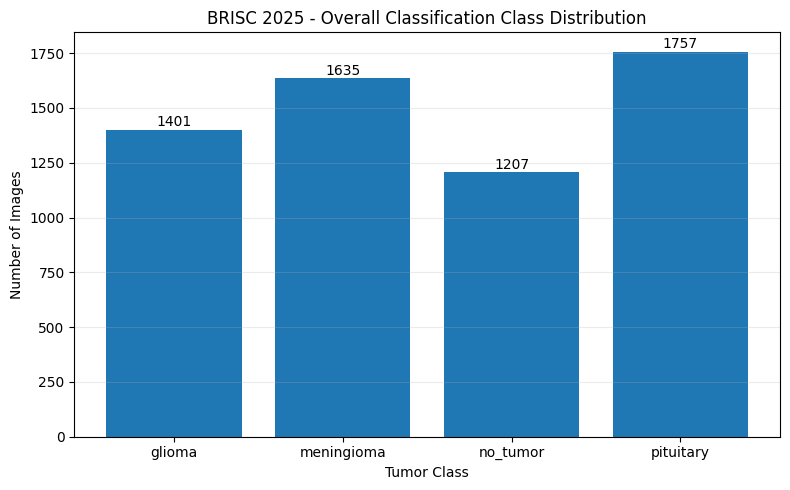

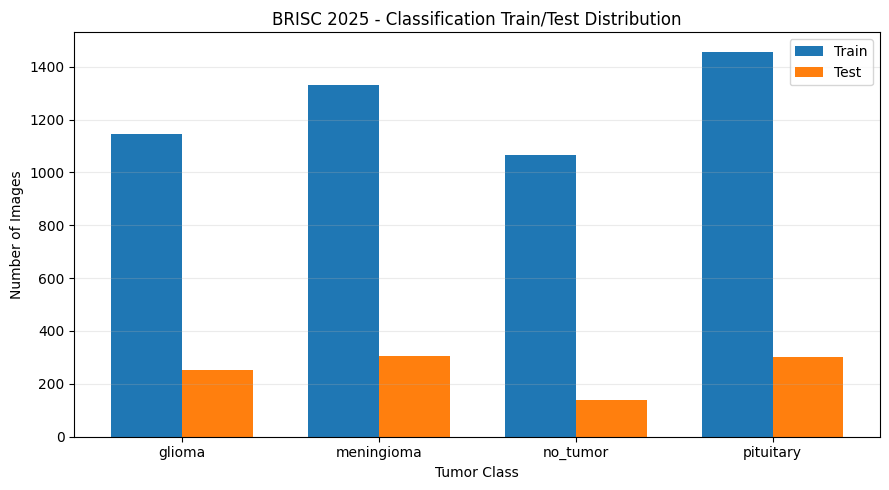


Classification table and graphs saved successfully.


In [2]:
# Analyze classification class distribution and compare official training and test splits.

CLASS_ORDER = ["glioma", "meningioma", "no_tumor", "pituitary"]

# Calculate class counts
overall_class_counts = (
    classification_df["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

train_class_counts = (
    classification_df[classification_df["split"] == "train"]["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

test_class_counts = (
    classification_df[classification_df["split"] == "test"]["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Create distribution table
class_distribution_df = pd.DataFrame({
    "train": train_class_counts,
    "test": test_class_counts,
    "total": overall_class_counts
})

class_distribution_df["train_percent"] = (
    100 * class_distribution_df["train"] / class_distribution_df["train"].sum()
)

class_distribution_df["test_percent"] = (
    100 * class_distribution_df["test"] / class_distribution_df["test"].sum()
)

class_distribution_df["overall_percent"] = (
    100 * class_distribution_df["total"] / class_distribution_df["total"].sum()
)

print("CLASSIFICATION CLASS DISTRIBUTION")
print("-" * 55)
display(class_distribution_df.round(2))

print("\nTotal images:", len(classification_df))
print("Training images:", train_class_counts.sum())
print("Testing images:", test_class_counts.sum())

# Plot 1: Overall class distribution
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASS_ORDER, overall_class_counts.values)

ax.set_title("BRISC 2025 - Overall Classification Class Distribution")
ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Images")
ax.grid(axis="y", alpha=0.25)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f"{int(bar.get_height())}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    FIGURES_ROOT / "eda_classification_overall_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot 2: Training versus test distribution
x = np.arange(len(CLASS_ORDER))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width / 2, train_class_counts.values, width, label="Train")
ax.bar(x + width / 2, test_class_counts.values, width, label="Test")

ax.set_title("BRISC 2025 - Classification Train/Test Distribution")
ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Images")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_ORDER)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_ROOT / "eda_classification_train_test_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save class distribution table
class_distribution_df.to_csv(
    TABLES_ROOT / "eda_classification_class_distribution.csv"
)

print("\nClassification table and graphs saved successfully.")

In [3]:
# Reconstruct confirmed cross-split duplicate records using decoded RGB image content.

import hashlib

def get_rgb_fingerprint(relative_path):
    image_path = get_dataset_path(relative_path)

    with Image.open(image_path) as img:
        rgb_image = img.convert("RGB")
        return hashlib.sha256(rgb_image.tobytes()).hexdigest()

# Generate fingerprints for the 6,000 classification images
classification_rgb_df = classification_df.copy()

classification_rgb_df["rgb_fingerprint"] = (
    classification_rgb_df["relative_path"].apply(get_rgb_fingerprint)
)

# Find fingerprints appearing in both official splits
split_counts = (
    classification_rgb_df.groupby("rgb_fingerprint")["split"].nunique()
)

cross_split_fingerprints = split_counts[split_counts > 1].index

confirmed_cross_split_records = classification_rgb_df[
    classification_rgb_df["rgb_fingerprint"].isin(cross_split_fingerprints)
].copy()

# Separate affected test and training records
test_leakage_df = confirmed_cross_split_records[
    confirmed_cross_split_records["split"] == "test"
].copy()

train_exclusion_df = confirmed_cross_split_records[
    confirmed_cross_split_records["split"] == "train"
].copy()

# Keep the names used in your friend's later notebook sections
confirmed_test_df = test_leakage_df.copy()
confirmed_train_df = train_exclusion_df.copy()

print("CONFIRMED CROSS-SPLIT RGB DUPLICATES")
print("-" * 55)
print("Images processed:", len(classification_rgb_df))
print("Duplicate groups:", len(cross_split_fingerprints))
print("Affected test records:", len(test_leakage_df))
print("Affected training records:", len(train_exclusion_df))

print("\nAffected test records by class:")
display(test_leakage_df["tumor_label"].value_counts())

print("\nAffected training records by class:")
display(train_exclusion_df["tumor_label"].value_counts())

CONFIRMED CROSS-SPLIT RGB DUPLICATES
-------------------------------------------------------
Images processed: 6000
Duplicate groups: 98
Affected test records: 101
Affected training records: 104

Affected test records by class:


tumor_label
meningioma    96
pituitary      5
Name: count, dtype: int64


Affected training records by class:


tumor_label
meningioma    97
pituitary      7
Name: count, dtype: int64

TEST-SET CONTAMINATION BY CLASS
-------------------------------------------------------


,official_test,confirmed_contaminated,remaining_test,contamination_percent
tumor_label,,,,
glioma,254,0,254,0.00
meningioma,306,96,210,31.37
no_tumor,140,0,140,0.00
pituitary,300,5,295,1.67



OVERALL TEST-SET SUMMARY
Official test images: 1000
Confirmed affected test records: 101
Remaining test records: 899
Overall contamination: 10.10%


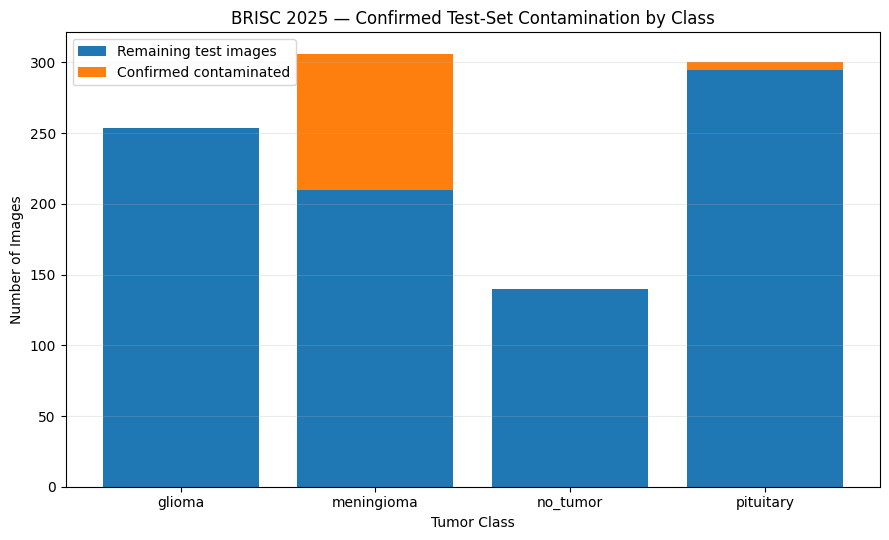

Contamination figure and table saved successfully.


In [4]:
# Quantify confirmed cross-split duplicate contamination in the official test set.

# Official test class counts
official_test_counts = (
    classification_df[classification_df["split"] == "test"]
    ["tumor_label"].value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Test images with confirmed matching training-image content
contaminated_test_counts = (
    test_leakage_df["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

# Test records without a confirmed cross-split match
remaining_test_counts = official_test_counts - contaminated_test_counts

# Build summary table
leakage_distribution_df = pd.DataFrame({
    "official_test": official_test_counts,
    "confirmed_contaminated": contaminated_test_counts,
    "remaining_test": remaining_test_counts
})

leakage_distribution_df["contamination_percent"] = (
    100 * contaminated_test_counts / official_test_counts
)

print("TEST-SET CONTAMINATION BY CLASS")
print("-" * 55)
display(leakage_distribution_df.round(2))

print("\nOVERALL TEST-SET SUMMARY")
print("Official test images:", int(official_test_counts.sum()))
print("Confirmed affected test records:", int(contaminated_test_counts.sum()))
print("Remaining test records:", int(remaining_test_counts.sum()))

print(
    "Overall contamination:",
    f"{100 * contaminated_test_counts.sum() / official_test_counts.sum():.2f}%"
)

# Plot confirmed contamination by class
x = np.arange(len(CLASS_ORDER))

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(
    x, remaining_test_counts.values,
    label="Remaining test images"
)

ax.bar(
    x, contaminated_test_counts.values,
    bottom=remaining_test_counts.values,
    label="Confirmed contaminated"
)

ax.set_title("BRISC 2025 — Confirmed Test-Set Contamination by Class")
ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Images")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_ORDER)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_ROOT / "eda_classification_test_leakage_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save the results
leakage_distribution_df.to_csv(
    TABLES_ROOT / "eda_classification_test_leakage_distribution.csv"
)

print("Contamination figure and table saved successfully.")

TRAINING-SIDE DUPLICATE DISTRIBUTION
-------------------------------------------------------


,official_train,confirmed_duplicate_train,remaining_train,affected_percent,remaining_percent
tumor_label,,,,,
glioma,1147,0,1147,0.00,100.00
meningioma,1329,97,1232,7.30,92.70
no_tumor,1067,0,1067,0.00,100.00
pituitary,1457,7,1450,0.48,99.52



OVERALL TRAINING SUMMARY
Official training images: 5000
Affected training records: 104
Remaining training records: 4896
Affected percentage: 2.08%


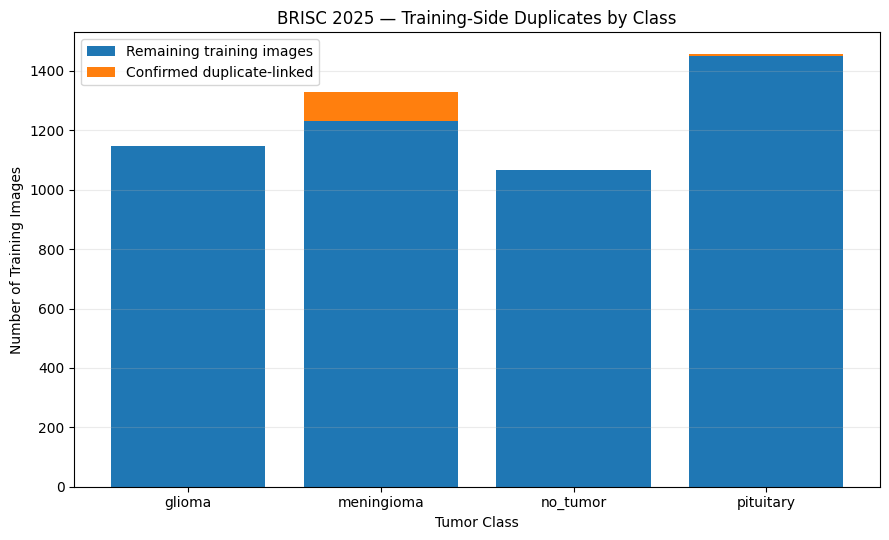


Training duplicate figure and table saved successfully.


In [5]:
# Analyze confirmed duplicate-linked training records by tumor class.

# Count affected and official training images by class
confirmed_train_counts = (
    train_exclusion_df["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

official_train_counts = (
    classification_df[classification_df["split"] == "train"]
    ["tumor_label"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
)

remaining_train_counts = official_train_counts - confirmed_train_counts

# Create training-side summary table
train_leakage_distribution_df = pd.DataFrame({
    "official_train": official_train_counts,
    "confirmed_duplicate_train": confirmed_train_counts,
    "remaining_train": remaining_train_counts
})

train_leakage_distribution_df["affected_percent"] = (
    100 * confirmed_train_counts / official_train_counts
)

train_leakage_distribution_df["remaining_percent"] = (
    100 * remaining_train_counts / official_train_counts
)

print("TRAINING-SIDE DUPLICATE DISTRIBUTION")
print("-" * 55)
display(train_leakage_distribution_df.round(2))

# Overall summary
total_official_train = int(official_train_counts.sum())
total_affected_train = int(confirmed_train_counts.sum())
total_remaining_train = int(remaining_train_counts.sum())

print("\nOVERALL TRAINING SUMMARY")
print("Official training images:", total_official_train)
print("Affected training records:", total_affected_train)
print("Remaining training records:", total_remaining_train)
print(
    "Affected percentage:",
    f"{100 * total_affected_train / total_official_train:.2f}%"
)

# Plot training-side duplicate distribution
x = np.arange(len(CLASS_ORDER))

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(
    x,
    remaining_train_counts.values,
    label="Remaining training images"
)

ax.bar(
    x,
    confirmed_train_counts.values,
    bottom=remaining_train_counts.values,
    label="Confirmed duplicate-linked"
)

ax.set_title("BRISC 2025 — Training-Side Duplicates by Class")
ax.set_xlabel("Tumor Class")
ax.set_ylabel("Number of Training Images")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_ORDER)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_ROOT / "eda_classification_train_duplicates_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save the summary table
train_leakage_distribution_df.to_csv(
    TABLES_ROOT / "eda_classification_train_duplicate_distribution.csv"
)

print("\nTraining duplicate figure and table saved successfully.")

MRI ACQUISITION METADATA
-------------------------------------------------------

Imaging plane counts:


plane_label
sagittal    2026
axial       1993
coronal     1981
Name: count, dtype: int64


MRI sequence counts:


sequence
T1    6000
Name: count, dtype: int64


Plane and sequence distribution:


sequence,T1,All
plane_label,,
axial,1993,1993
coronal,1981,1981
sagittal,2026,2026
All,6000,6000



CLASSIFICATION IMAGES BY MRI PLANE


split,test,train,total,overall_percent
plane_label,,,,
axial,398,1595,1993,33.22
coronal,305,1676,1981,33.02
sagittal,297,1729,2026,33.77



CONFIRMED DUPLICATION BY MRI PLANE


,official_train,affected_train,official_test,affected_test,train_affected_percent,test_contamination_percent
axial,1595,64,398,63,4.01,15.83
coronal,1676,24,305,22,1.43,7.21
sagittal,1729,16,297,16,0.93,5.39


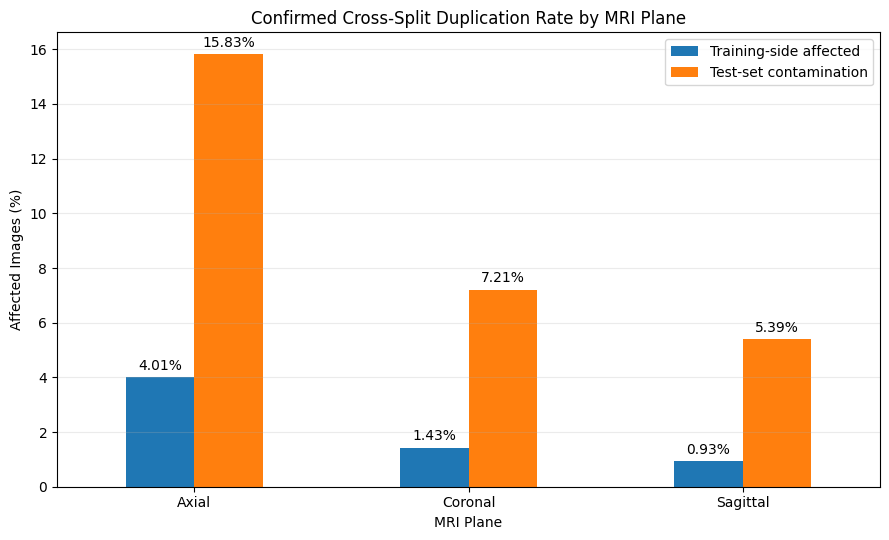


CHI-SQUARE TEST: MRI PLANE AND TEST CONTAMINATION
-------------------------------------------------------
Chi-square statistic: 24.4518
Degrees of freedom: 2
p-value: 4.901814506e-06
Cramer's V: 0.1564

Pearson residuals:


,affected_residual,unaffected_residual
axial,3.596,-1.205
coronal,-1.586,0.532
sagittal,-2.556,0.857



MRI metadata analysis completed.
Figures and statistical tables saved successfully.


In [6]:
# Analyze MRI acquisition metadata and test whether duplicate contamination is associated with MRI plane.

from scipy.stats import chi2_contingency

# 1. Examine imaging planes and MRI sequences
print("MRI ACQUISITION METADATA")
print("-" * 55)

print("\nImaging plane counts:")
display(classification_df["plane_label"].value_counts())

print("\nMRI sequence counts:")
display(classification_df["sequence"].value_counts())

print("\nPlane and sequence distribution:")
display(pd.crosstab(
    classification_df["plane_label"],
    classification_df["sequence"],
    margins=True
))

# 2. Compare imaging planes across official splits
plane_split_table = pd.crosstab(
    classification_df["plane_label"],
    classification_df["split"]
)

plane_split_table["total"] = plane_split_table.sum(axis=1)
plane_split_table["overall_percent"] = (
    100 * plane_split_table["total"] / len(classification_df)
)

print("\nCLASSIFICATION IMAGES BY MRI PLANE")
display(plane_split_table.round(2))

# 3. Calculate confirmed duplicate records by MRI plane
planes = sorted(classification_df["plane_label"].dropna().unique())

plane_leakage_df = pd.DataFrame(index=planes)

plane_leakage_df["official_train"] = (
    classification_df[classification_df["split"] == "train"]
    ["plane_label"].value_counts().reindex(planes, fill_value=0)
)

plane_leakage_df["affected_train"] = (
    train_exclusion_df["plane_label"]
    .value_counts().reindex(planes, fill_value=0)
)

plane_leakage_df["official_test"] = (
    classification_df[classification_df["split"] == "test"]
    ["plane_label"].value_counts().reindex(planes, fill_value=0)
)

plane_leakage_df["affected_test"] = (
    test_leakage_df["plane_label"]
    .value_counts().reindex(planes, fill_value=0)
)

plane_leakage_df["train_affected_percent"] = (
    100 * plane_leakage_df["affected_train"]
    / plane_leakage_df["official_train"]
)

plane_leakage_df["test_contamination_percent"] = (
    100 * plane_leakage_df["affected_test"]
    / plane_leakage_df["official_test"]
)

print("\nCONFIRMED DUPLICATION BY MRI PLANE")
display(plane_leakage_df.round(2))

# 4. Visualize duplication rates by MRI plane
plot_df = plane_leakage_df[
    ["train_affected_percent", "test_contamination_percent"]
]

ax = plot_df.plot(kind="bar", figsize=(9, 5.5))

ax.set_title("Confirmed Cross-Split Duplication Rate by MRI Plane")
ax.set_xlabel("MRI Plane")
ax.set_ylabel("Affected Images (%)")
ax.set_xticklabels(
    [p.capitalize() for p in plot_df.index],
    rotation=0
)
ax.legend(["Training-side affected", "Test-set contamination"])
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig(
    FIGURES_ROOT / "eda_classification_duplication_rate_by_plane.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 5. Chi-square test of association
contingency_table = plane_leakage_df[
    ["affected_test", "official_test"]
].copy()

contingency_table["unaffected_test"] = (
    contingency_table["official_test"]
    - contingency_table["affected_test"]
)

contingency_table = contingency_table[
    ["affected_test", "unaffected_test"]
]

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

n = contingency_table.to_numpy().sum()
cramers_v = np.sqrt(
    chi2 / (n * min(contingency_table.shape[0] - 1,
                    contingency_table.shape[1] - 1))
)

residual_df = pd.DataFrame(
    (contingency_table.to_numpy() - expected) / np.sqrt(expected),
    index=contingency_table.index,
    columns=["affected_residual", "unaffected_residual"]
)

print("\nCHI-SQUARE TEST: MRI PLANE AND TEST CONTAMINATION")
print("-" * 55)
print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("p-value:", f"{p_value:.10g}")
print("Cramer's V:", round(cramers_v, 4))

print("\nPearson residuals:")
display(residual_df.round(3))

# 6. Save all results
plane_split_table.to_csv(
    TABLES_ROOT / "eda_classification_plane_split_distribution.csv"
)

plane_leakage_df.to_csv(
    TABLES_ROOT / "eda_classification_duplication_by_plane.csv"
)

pd.DataFrame({
    "chi_square": [chi2],
    "degrees_of_freedom": [dof],
    "p_value": [p_value],
    "cramers_v": [cramers_v]
}).to_csv(
    TABLES_ROOT / "eda_classification_plane_contamination_chi_square.csv",
    index=False
)

residual_df.to_csv(
    TABLES_ROOT / "eda_classification_plane_contamination_residuals.csv"
)

print("\nMRI metadata analysis completed.")
print("Figures and statistical tables saved successfully.")

In [7]:
# Analyze segmentation MRI counts, tumor classes, dataset splits and imaging planes.

# 1. Dataset overview
print("SEGMENTATION DATASET SUMMARY")
print("-" * 55)
print("Total segmentation records:", len(segmentation_df))
print("MRI images:", len(segmentation_mri_df))
print("Masks:", len(segmentation_mask_df))

print("\nMRI images by split:")
display(segmentation_mri_df["split"].value_counts())

print("\nMasks by split:")
display(segmentation_mask_df["split"].value_counts())

# 2. Tumor-class distribution (MRI images only)
seg_class_counts = pd.crosstab(
    segmentation_mri_df["tumor_label"],
    segmentation_mri_df["split"]
).reindex(columns=["train", "test"], fill_value=0)

seg_class_counts["total"] = (
    seg_class_counts["train"] + seg_class_counts["test"]
)

seg_class_counts["train_percent"] = (
    100 * seg_class_counts["train"] / seg_class_counts["train"].sum()
)

seg_class_counts["test_percent"] = (
    100 * seg_class_counts["test"] / seg_class_counts["test"].sum()
)

seg_class_counts["overall_percent"] = (
    100 * seg_class_counts["total"] / seg_class_counts["total"].sum()
)

print("\nSEGMENTATION TUMOR-CLASS DISTRIBUTION")
display(seg_class_counts.round(2))

# 3. MRI plane distribution
seg_plane_counts = pd.crosstab(
    segmentation_mri_df["plane_label"],
    segmentation_mri_df["split"]
).reindex(columns=["train", "test"], fill_value=0)

seg_plane_counts["total"] = (
    seg_plane_counts["train"] + seg_plane_counts["test"]
)

seg_plane_counts["overall_percent"] = (
    100 * seg_plane_counts["total"] / seg_plane_counts["total"].sum()
)

seg_plane_counts["train_percent"] = (
    100 * seg_plane_counts["train"] / seg_plane_counts["train"].sum()
)

seg_plane_counts["test_percent"] = (
    100 * seg_plane_counts["test"] / seg_plane_counts["test"].sum()
)

print("\nSEGMENTATION MRI PLANE DISTRIBUTION")
display(seg_plane_counts.round(2))

# 4. Tumor class versus MRI plane
seg_class_plane_table = pd.crosstab(
    segmentation_mri_df["tumor_label"],
    segmentation_mri_df["plane_label"],
    margins=True
)

print("\nSEGMENTATION CLASS × MRI PLANE")
display(seg_class_plane_table)

# 5. Save all distribution tables
seg_class_counts.to_csv(
    TABLES_ROOT / "eda_segmentation_class_distribution.csv"
)

seg_plane_counts.to_csv(
    TABLES_ROOT / "eda_segmentation_plane_distribution.csv"
)

seg_class_plane_table.to_csv(
    TABLES_ROOT / "eda_segmentation_class_by_plane.csv"
)

print("\nSegmentation distribution tables saved successfully.")

SEGMENTATION DATASET SUMMARY
-------------------------------------------------------
Total segmentation records: 9586
MRI images: 4793
Masks: 4793

MRI images by split:


split
train    3933
test      860
Name: count, dtype: int64


Masks by split:


split
train    3933
test      860
Name: count, dtype: int64


SEGMENTATION TUMOR-CLASS DISTRIBUTION


split,train,test,total,train_percent,test_percent,overall_percent
tumor_label,,,,,,
glioma,1147,254,1401,29.16,29.53,29.23
meningioma,1329,306,1635,33.79,35.58,34.11
pituitary,1457,300,1757,37.05,34.88,36.66



SEGMENTATION MRI PLANE DISTRIBUTION


split,train,test,total,overall_percent,train_percent,test_percent
plane_label,,,,,,
axial,1243,346,1589,33.15,31.60,40.23
coronal,1366,257,1623,33.86,34.73,29.88
sagittal,1324,257,1581,32.99,33.66,29.88



SEGMENTATION CLASS × MRI PLANE


plane_label,axial,coronal,sagittal,All
tumor_label,,,,
glioma,479,511,411,1401
meningioma,560,512,563,1635
pituitary,550,600,607,1757
All,1589,1623,1581,4793



Segmentation distribution tables saved successfully.


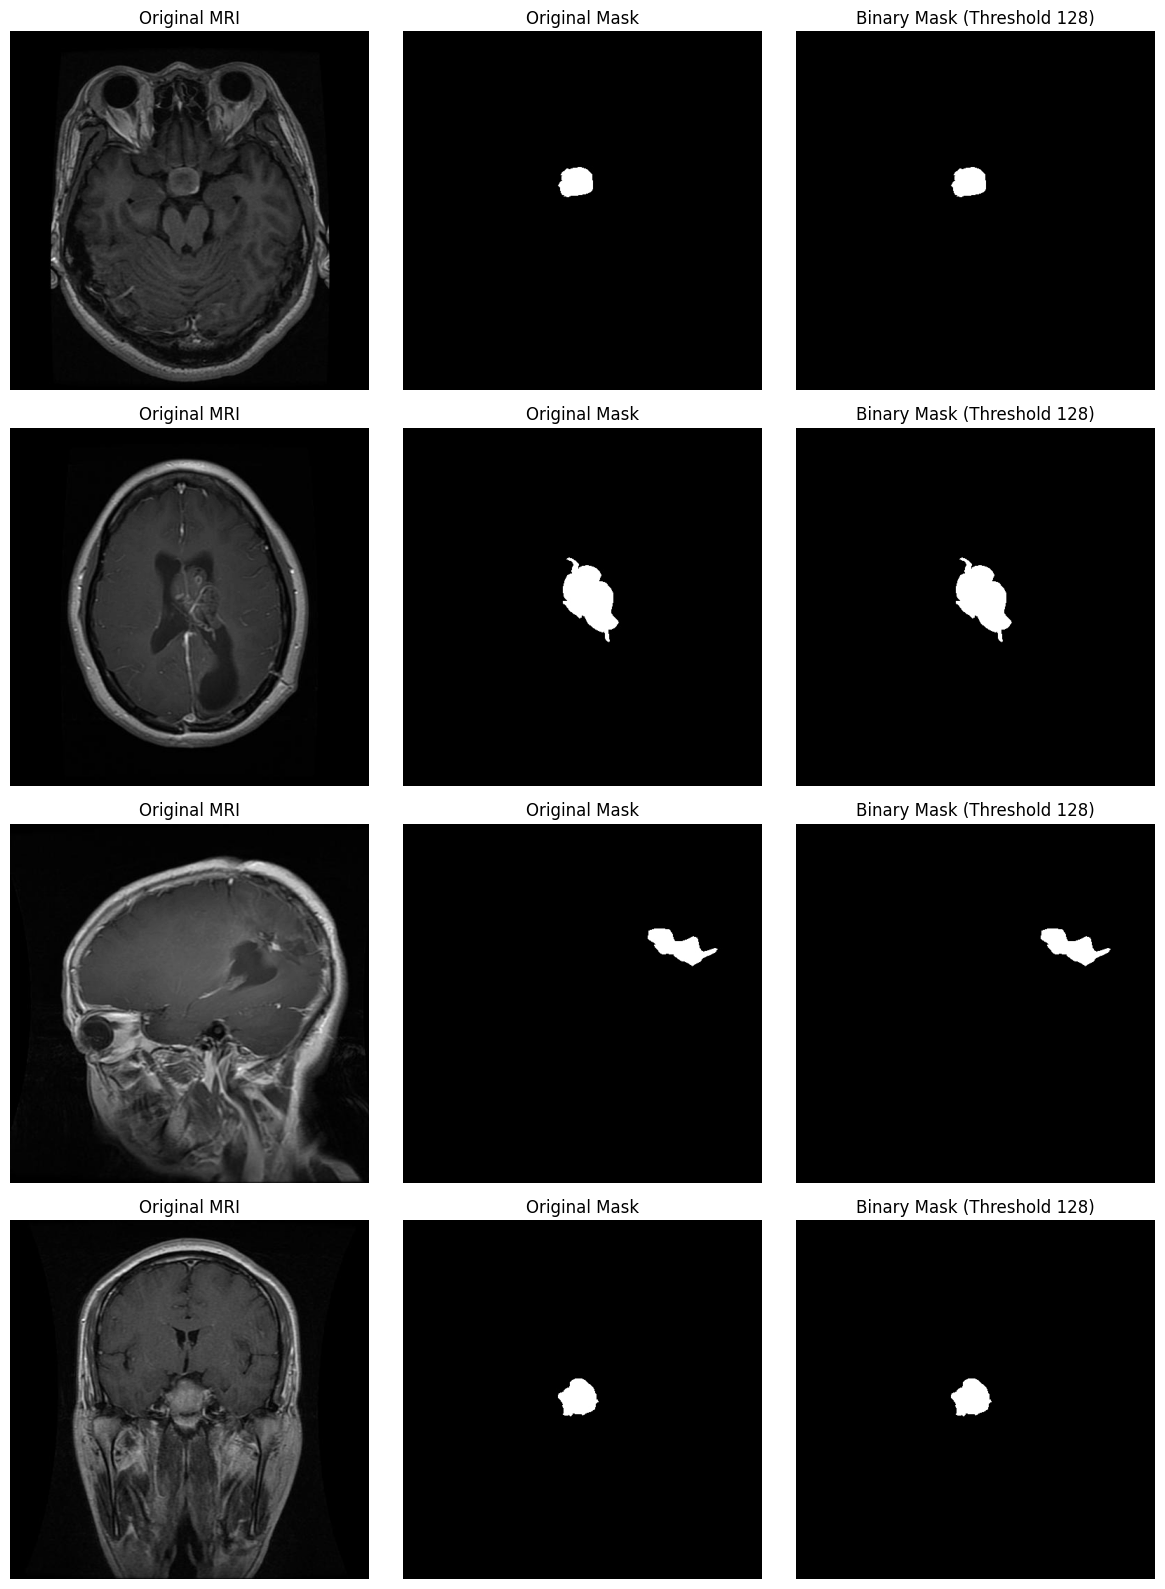

Visual MRI-mask verification completed.


In [8]:
# Visually compare representative MRI images, original masks and binary masks.

sample_masks = segmentation_mask_df.sample(
    n=4,
    random_state=42
)

fig, axes = plt.subplots(
    len(sample_masks), 3,
    figsize=(12, 4 * len(sample_masks))
)

for row_idx, (_, mask_row) in enumerate(sample_masks.iterrows()):

    image_path = get_dataset_path(mask_row["linked_image"])
    mask_path = get_dataset_path(mask_row["relative_path"])

    with Image.open(image_path) as img:
        image_array = np.array(img.convert("L"))

    with Image.open(mask_path) as mask:
        mask_array = np.array(mask.convert("L"))

    # Previously verified threshold from Notebook 02
    binary_mask = mask_array >= 128

    axes[row_idx, 0].imshow(image_array, cmap="gray")
    axes[row_idx, 0].set_title("Original MRI")

    axes[row_idx, 1].imshow(mask_array, cmap="gray", vmin=0, vmax=255)
    axes[row_idx, 1].set_title("Original Mask")

    axes[row_idx, 2].imshow(binary_mask, cmap="gray")
    axes[row_idx, 2].set_title("Binary Mask (Threshold 128)")

    for ax in axes[row_idx]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURES_ROOT / "eda_segmentation_mri_mask_visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visual MRI-mask verification completed.")

In [9]:
# Calculate tumor foreground area and percentage for all 4,793 segmentation masks.

tumor_area_records = []

print("Computing tumor-region statistics...")

for _, row in segmentation_mask_df.iterrows():

    mask_path = get_dataset_path(row["relative_path"])

    with Image.open(mask_path) as mask:
        mask_array = np.array(mask.convert("L"))

    # Convert the near-binary grayscale mask into a binary mask
    binary_mask = mask_array >= 128

    foreground_pixels = int(binary_mask.sum())
    total_pixels = int(binary_mask.size)

    foreground_percent = (
        100 * foreground_pixels / total_pixels
    )

    tumor_area_records.append({
        "filename": row["filename"],
        "split": row["split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "width": mask_array.shape[1],
        "height": mask_array.shape[0],
        "foreground_pixels": foreground_pixels,
        "total_pixels": total_pixels,
        "tumor_percent": foreground_percent
    })

tumor_area_df = pd.DataFrame(tumor_area_records)

print("\nTUMOR REGION ANALYSIS")
print("-" * 55)
print("Masks analysed:", len(tumor_area_df))

display(tumor_area_df.head())

print("\nOVERALL TUMOR-REGION SUMMARY")
display(
    tumor_area_df[
        ["foreground_pixels", "tumor_percent"]
    ].describe().round(3)
)

# Save tumor-region measurements
tumor_area_df.to_csv(
    TABLES_ROOT / "eda_segmentation_tumor_area_records.csv",
    index=False
)

print("\nTumor-area records saved successfully.")

Computing tumor-region statistics...

TUMOR REGION ANALYSIS
-------------------------------------------------------
Masks analysed: 4793


,filename,split,tumor_label,plane_label,width,height,foreground_pixels,total_pixels,tumor_percent
0,brisc2025_test_00001_gl_ax_t1.png,test,glioma,axial,512,512,1151,262144,0.439072
1,brisc2025_test_00002_gl_ax_t1.png,test,glioma,axial,512,512,2181,262144,0.831985
2,brisc2025_test_00003_gl_ax_t1.png,test,glioma,axial,512,512,5789,262144,2.208328
3,brisc2025_test_00004_gl_ax_t1.png,test,glioma,axial,512,512,3989,262144,1.521683
4,brisc2025_test_00005_gl_ax_t1.png,test,glioma,axial,512,512,1192,262144,0.454712



OVERALL TUMOR-REGION SUMMARY


,foreground_pixels,tumor_percent
count,4793.000,4793.000
mean,4131.882,1.694
std,3748.903,1.497
min,23.000,0.009
25%,1806.000,0.710
50%,3199.000,1.255
75%,5239.000,2.144
max,73320.000,17.347



Tumor-area records saved successfully.


TUMOR REGION SIZE BY CLASS
------------------------------------------------------------


,cases,mean,median,std,q1,q3,minimum,maximum
tumor_label,,,,,,,,
glioma,1401,1.867,1.521,1.481,0.816,2.456,0.053,9.770
meningioma,1635,2.245,1.736,1.828,0.995,2.976,0.009,17.347
pituitary,1757,1.042,0.864,0.727,0.544,1.354,0.058,6.487



TUMOR REGION SIZE BY CLASS AND SPLIT
------------------------------------------------------------


cases   mean  median    std     q1     q3  minimum  maximum
tumor_label split                                                             
glioma      test     254  1.941   1.282  1.665  0.792  2.711    0.095    9.770
            train   1147  1.850   1.556  1.437  0.826  2.415    0.053    8.895
meningioma  test     306  2.870   2.066  2.364  1.182  3.784    0.208   15.450
            train   1329  2.102   1.670  1.649  0.977  2.792    0.009   17.347
pituitary   test     300  0.891   0.698  0.637  0.479  1.216    0.082    4.876
            train   1457  1.073   0.904  0.740  0.563  1.382    0.058    6.487

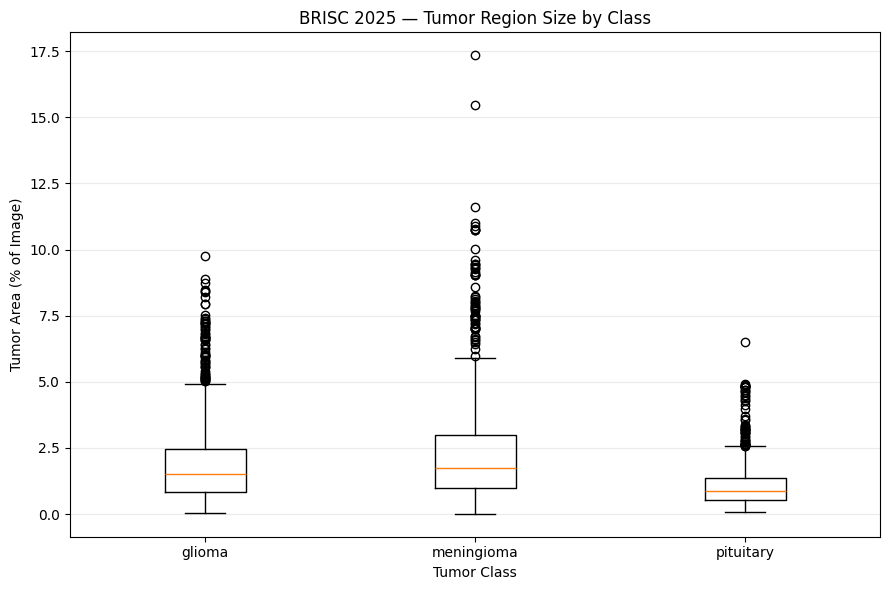

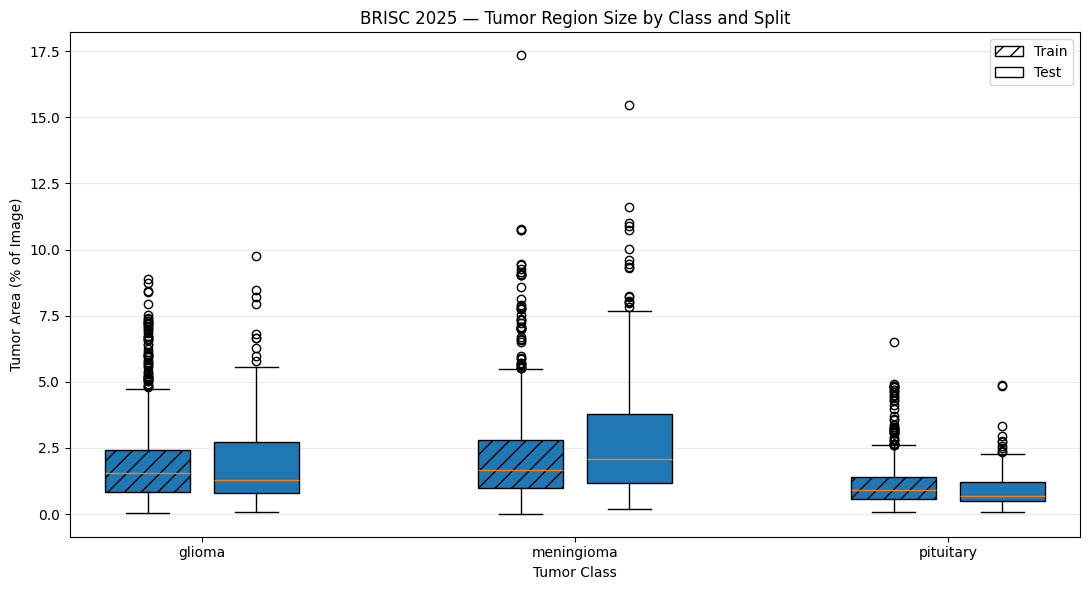


Tumor-region summary tables and figures saved successfully.


In [10]:
# Summarize and visualize tumor-region sizes by class and dataset split.

SEG_CLASS_ORDER = ["glioma", "meningioma", "pituitary"]

# 1. Calculate grouped tumor-region statistics
def grouped_tumor_summary(df, group_columns):
    grouped = df.groupby(group_columns)["tumor_percent"]

    summary = grouped.agg(
        cases="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )

    summary["q1"] = grouped.quantile(0.25)
    summary["q3"] = grouped.quantile(0.75)

    return summary[
        ["cases", "mean", "median", "std", "q1", "q3", "minimum", "maximum"]
    ]

class_tumor_summary = grouped_tumor_summary(
    tumor_area_df, ["tumor_label"]
)

class_split_tumor_summary = grouped_tumor_summary(
    tumor_area_df, ["tumor_label", "split"]
)

print("TUMOR REGION SIZE BY CLASS")
print("-" * 60)
display(class_tumor_summary.round(3))

print("\nTUMOR REGION SIZE BY CLASS AND SPLIT")
print("-" * 60)
display(class_split_tumor_summary.round(3))

# 2. Boxplot: tumor-region size by class
class_data = [
    tumor_area_df.loc[
        tumor_area_df["tumor_label"] == label, "tumor_percent"
    ].values
    for label in SEG_CLASS_ORDER
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    class_data,
    tick_labels=SEG_CLASS_ORDER,
    showfliers=True
)

ax.set_title("BRISC 2025 — Tumor Region Size by Class")
ax.set_xlabel("Tumor Class")
ax.set_ylabel("Tumor Area (% of Image)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_ROOT / "eda_segmentation_tumor_area_by_class.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 3. Boxplot: tumor-region size by class and split
plot_data = []
positions = []
tick_positions = []

current_position = 1

for label in SEG_CLASS_ORDER:
    train_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "train")
    ]["tumor_percent"].values

    test_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "test")
    ]["tumor_percent"].values

    plot_data.extend([train_values, test_values])
    positions.extend([current_position, current_position + 0.7])
    tick_positions.append(current_position + 0.35)

    current_position += 2.4

fig, ax = plt.subplots(figsize=(11, 6))

bp = ax.boxplot(
    plot_data,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showfliers=True
)

for i, box in enumerate(bp["boxes"]):
    if i % 2 == 0:
        box.set_hatch("//")

from matplotlib.patches import Patch

ax.legend(handles=[
    Patch(facecolor="white", edgecolor="black", hatch="//", label="Train"),
    Patch(facecolor="white", edgecolor="black", label="Test")
])

ax.set_xticks(tick_positions)
ax.set_xticklabels(SEG_CLASS_ORDER)
ax.set_xlabel("Tumor Class")
ax.set_ylabel("Tumor Area (% of Image)")
ax.set_title("BRISC 2025 — Tumor Region Size by Class and Split")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_ROOT / "eda_segmentation_tumor_area_train_test.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 4. Save statistical summaries
class_tumor_summary.to_csv(
    TABLES_ROOT / "eda_segmentation_tumor_area_by_class.csv"
)

class_split_tumor_summary.to_csv(
    TABLES_ROOT / "eda_segmentation_tumor_area_by_class_split.csv"
)

print("\nTumor-region summary tables and figures saved successfully.")

In [11]:
# Statistically compare tumor-region sizes between training and test splits using Mann–Whitney U and Holm correction.

alpha = 0.05
results = []

for label in SEG_CLASS_ORDER:

    train_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "train")
    ]["tumor_percent"].dropna()

    test_values = tumor_area_df[
        (tumor_area_df["tumor_label"] == label) &
        (tumor_area_df["split"] == "test")
    ]["tumor_percent"].dropna()

    if len(train_values) == 0 or len(test_values) == 0:
        raise ValueError(f"Missing train or test observations for {label}")

    u_stat, p_value = mannwhitneyu(
        train_values,
        test_values,
        alternative="two-sided"
    )

    n1 = len(train_values)
    n2 = len(test_values)

    # Signed rank-biserial effect size
    rank_biserial = (2 * u_stat / (n1 * n2)) - 1

    results.append({
        "tumor_label": label,
        "train_n": n1,
        "test_n": n2,
        "train_median": train_values.median(),
        "test_median": test_values.median(),
        "U_statistic": u_stat,
        "p_value": p_value,
        "rank_biserial_effect": rank_biserial
    })

tumor_area_mwu_df = pd.DataFrame(results)

# Apply Holm correction to the three p-values
raw_p_values = tumor_area_mwu_df["p_value"].to_numpy()
m = len(raw_p_values)

order = np.argsort(raw_p_values)
sorted_p = raw_p_values[order]

holm_sorted = np.maximum.accumulate(
    (m - np.arange(m)) * sorted_p
)

holm_adjusted = np.empty(m)
holm_adjusted[order] = np.minimum(holm_sorted, 1.0)

tumor_area_mwu_df["holm_adjusted_p"] = holm_adjusted

tumor_area_mwu_df["significant_after_holm"] = (
    tumor_area_mwu_df["holm_adjusted_p"] < alpha
)

# Display results
print("MANN-WHITNEY U TEST WITH HOLM CORRECTION")
print("-" * 65)

display(
    tumor_area_mwu_df.round({
        "train_median": 4,
        "test_median": 4,
        "U_statistic": 2,
        "p_value": 10,
        "holm_adjusted_p": 10,
        "rank_biserial_effect": 4
    })
)

# Interpret effect size and significance
print("\nSTATISTICAL INTERPRETATION")
print("-" * 65)

for _, row in tumor_area_mwu_df.iterrows():

    effect = abs(row["rank_biserial_effect"])

    if effect < 0.1:
        effect_label = "negligible"
    elif effect < 0.3:
        effect_label = "small"
    elif effect < 0.5:
        effect_label = "moderate"
    else:
        effect_label = "large"

    significance = (
        "Statistically significant"
        if row["significant_after_holm"]
        else "Not statistically significant"
    )

    direction = (
        "Training distribution tends higher"
        if row["rank_biserial_effect"] > 0
        else "Test distribution tends higher"
        if row["rank_biserial_effect"] < 0
        else "No directional difference"
    )

    print(
        f"{row['tumor_label']}: {significance}; "
        f"adjusted p = {row['holm_adjusted_p']:.6g}; "
        f"{effect_label} effect; {direction}."
    )

# Save the complete statistical results
stats_path = (
    TABLES_ROOT /
    "eda_segmentation_tumor_area_train_test_statistics.csv"
)

tumor_area_mwu_df.to_csv(stats_path, index=False)

print("\nStatistical results saved to:")
print(stats_path)

MANN-WHITNEY U TEST WITH HOLM CORRECTION
-----------------------------------------------------------------


,tumor_label,train_n,test_n,train_median,test_median,U_statistic,p_value,rank_biserial_effect,holm_adjusted_p,significant_after_holm
0,glioma,1147,254,1.5560,1.2821,147091.5,8.074362e-01,0.0098,0.807436,False
1,meningioma,1329,306,1.6705,2.0665,165500.5,3.747000e-07,-0.1861,0.000001,True
2,pituitary,1457,300,0.9037,0.6981,255350.0,4.251800e-06,0.1684,0.000009,True



STATISTICAL INTERPRETATION
-----------------------------------------------------------------
glioma: Not statistically significant; adjusted p = 0.807436; negligible effect; Training distribution tends higher.
meningioma: Statistically significant; adjusted p = 1.12415e-06; small effect; Test distribution tends higher.
pituitary: Statistically significant; adjusted p = 8.50369e-06; small effect; Training distribution tends higher.

Statistical results saved to:
/Users/krittikaroy/Brain Tumor/outputs/tables/eda_segmentation_tumor_area_train_test_statistics.csv


In [12]:
# Generate and save the final BRISC EDA summary using actual analysis results.

eda_summary_records = []

def add_finding(category, metric, value, status="Verified"):
    eda_summary_records.append({
        "category": category,
        "metric": metric,
        "value": value,
        "status": status
    })

# 1. Classification dataset
add_finding("classification", "total_images", len(classification_df))
add_finding(
    "classification", "training_images",
    int((classification_df["split"] == "train").sum())
)
add_finding(
    "classification", "testing_images",
    int((classification_df["split"] == "test").sum())
)

# Confirmed RGB cross-split duplicates
add_finding(
    "classification_leakage", "cross_split_duplicate_groups",
    len(cross_split_fingerprints)
)
add_finding(
    "classification_leakage", "affected_test_records",
    len(test_leakage_df)
)
add_finding(
    "classification_leakage", "test_contamination_percent",
    round(100 * len(test_leakage_df) /
          (classification_df["split"] == "test").sum(), 3)
)
add_finding(
    "classification_leakage", "affected_training_records",
    len(train_exclusion_df)
)

# 2. MRI-plane contamination statistics
add_finding("classification_metadata", "chi_square", round(float(chi2), 4))
add_finding("classification_metadata", "degrees_of_freedom", int(dof))
add_finding("classification_metadata", "p_value", float(p_value))
add_finding("classification_metadata", "cramers_v", round(float(cramers_v), 4))

# 3. Segmentation dataset
add_finding("segmentation", "MRI_mask_pairs", len(segmentation_mri_df))
add_finding(
    "segmentation", "training_cases",
    int((segmentation_mri_df["split"] == "train").sum())
)
add_finding(
    "segmentation", "testing_cases",
    int((segmentation_mri_df["split"] == "test").sum())
)

# Class-wise segmentation counts
for label, count in seg_class_counts["total"].items():
    add_finding("segmentation_class", f"{label}_cases", int(count))

# MRI-plane distribution
for plane, count in seg_plane_counts["total"].items():
    add_finding("segmentation_plane", f"{plane}_cases", int(count))

# 4. Findings from Notebook 02
add_finding(
    "segmentation_integrity", "MRI_cross_split_exact_hash_overlaps",
    7, "Requires review"
)
add_finding(
    "segmentation_integrity", "mask_cross_split_exact_hash_overlaps",
    0, "No exact overlap"
)
add_finding(
    "segmentation_mask", "binary_threshold", 128
)
add_finding(
    "segmentation_mask", "observed_pixel_encoding",
    "Background: 0-10; foreground: 246-255"
)

# 5. Tumor-region statistics
overall_area = tumor_area_df["tumor_percent"]

for metric, value in {
    "mean_tumor_percent": overall_area.mean(),
    "median_tumor_percent": overall_area.median(),
    "minimum_tumor_percent": overall_area.min(),
    "maximum_tumor_percent": overall_area.max()
}.items():
    add_finding(
        "segmentation_tumor_area",
        metric,
        round(float(value), 4)
    )

# Class-wise mean tumor area
for label, row in class_tumor_summary.iterrows():
    add_finding(
        "segmentation_tumor_area_by_class",
        f"{label}_mean_percent",
        round(float(row["mean"]), 4)
    )

# 6. Mann-Whitney and Holm-corrected results
for _, row in tumor_area_mwu_df.iterrows():
    label = row["tumor_label"]

    add_finding(
        "segmentation_statistical_test",
        f"{label}_holm_adjusted_p",
        float(row["holm_adjusted_p"])
    )
    add_finding(
        "segmentation_statistical_test",
        f"{label}_rank_biserial_effect",
        round(float(row["rank_biserial_effect"]), 4)
    )

# Create and display the final summary
eda_summary_df = pd.DataFrame(eda_summary_records)

print("FINAL BRISC EDA KEY-FINDING SUMMARY")
print("-" * 65)
display(eda_summary_df)

# Save summary
summary_path = TABLES_ROOT / "eda_final_key_findings_summary.csv"

eda_summary_df.to_csv(summary_path, index=False)

print("\nFinal EDA summary saved successfully:")
print(summary_path)

FINAL BRISC EDA KEY-FINDING SUMMARY
-----------------------------------------------------------------


,category,metric,value,status
0,classification,total_images,6000,Verified
1,classification,training_images,5000,Verified
2,classification,testing_images,1000,Verified
3,classification_leakage,cross_split_duplicate_groups,98,Verified
4,classification_leakage,affected_test_records,101,Verified
5,classification_leakage,test_contamination_percent,10.1,Verified
6,classification_leakage,affected_training_records,104,Verified
7,classification_metadata,chi_square,24.4518,Verified
8,classification_metadata,degrees_of_freedom,2,Verified
9,classification_metadata,p_value,0.000004,Verified



Final EDA summary saved successfully:
/Users/krittikaroy/Brain Tumor/outputs/tables/eda_final_key_findings_summary.csv


In [13]:
# Correct the chi-square p-value in the final EDA summary using the saved Cell 6 result.

chi_square_result = pd.read_csv(
    TABLES_ROOT / "eda_classification_plane_contamination_chi_square.csv"
).iloc[0]

eda_summary_df.loc[
    (eda_summary_df["category"] == "classification_metadata") &
    (eda_summary_df["metric"] == "p_value"),
    "value"
] = float(chi_square_result["p_value"])

eda_summary_df.to_csv(
    TABLES_ROOT / "eda_final_key_findings_summary.csv",
    index=False
)

print("Final summary corrected successfully.")
display(
    eda_summary_df[
        eda_summary_df["category"] == "classification_metadata"
    ]
)

Final summary corrected successfully.


,category,metric,value,status
7,classification_metadata,chi_square,24.4518,Verified
8,classification_metadata,degrees_of_freedom,2,Verified
9,classification_metadata,p_value,0.000005,Verified
10,classification_metadata,cramers_v,0.1564,Verified


In [ ]:
# Notebook 03 – Exploratory Data Analysis (EDA)

## 1. Objective

The objective of this notebook was to explore the BRISC 2025 brain MRI dataset, understand its classification and segmentation distributions, investigate potential duplicate-related data contamination, and analyse tumor-region characteristics.

## 2. Classification Analysis

- Examined the distribution of glioma, meningioma, pituitary and no-tumor images.
- Compared class distributions across the official training and testing splits.
- Investigated confirmed cross-split duplicate images using decoded RGB fingerprints.
- Examined the relationship between MRI acquisition planes and test-set contamination using the Chi-square test and Cramér's V.

## 3. Segmentation Analysis

- Examined the distribution of segmentation MRI images across tumor classes, MRI planes and dataset splits.
- Visually inspected representative MRI images and their corresponding segmentation masks.
- Used a threshold of 128 to obtain binary foreground masks, based on the mask pixel-value inspection performed in Notebook 02.
- Calculated tumor-region pixel counts and foreground percentages for all segmentation masks.
- Compared tumor-region percentages across tumor classes and training/testing splits.

## 4. Statistical Analysis

- Used the Mann–Whitney U test to compare tumor-region percentages between training and testing groups.
- Applied Holm correction to account for multiple statistical comparisons.
- Calculated rank-biserial effect sizes to assess the magnitude and direction of differences.

## 5. Important Data Integrity Considerations

Notebook 02 identified exact and decoded-pixel duplicate records across the classification splits, as well as seven exact-hash overlaps among segmentation MRI images. No exact cross-split hash overlap was detected among segmentation masks.

Perceptual-hash candidates were treated as potential similarities, not automatically classified as confirmed duplicates.

The dataset does not provide sufficient reliable patient identifiers to establish patient-level independence conclusively.

## 6. Conclusion

The exploratory analysis provides an overview of the BRISC 2025 dataset, its classification and segmentation distributions, MRI acquisition characteristics, duplicate-related contamination and tumor-region measurements.

These findings provide a foundation for subsequent preprocessing, model development and evaluation. Original dataset files and the official test split were preserved throughout the analysis.

**Note:** Statistical significance and effect-size interpretations should be reported according to the actual outputs generated in this notebook.